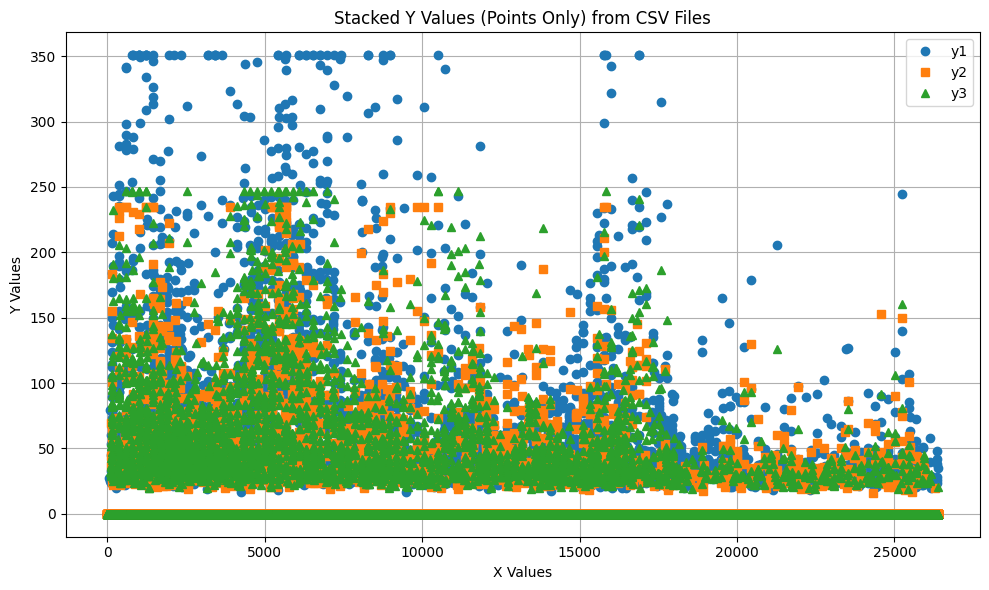

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_stacked_y_values_from_files(file1, file2, file3):
    """
    Reads data from three CSV files, matches the x-values (first column),
    and plots the y-values (second column) as stacked y-values (points only).

    Parameters
    ----------
    file1 : str
        Path to the first CSV file.
    file2 : str
        Path to the second CSV file.
    file3 : str
        Path to the third CSV file.

    Returns
    -------
    None
    """
    # Read data from the three files
    df1 = pd.read_csv(file1)
    df2 = pd.read_csv(file2)
    df3 = pd.read_csv(file3)

    # Ensure the first column is the x-values and the second column is the y-values
    x1, y1 = df1.iloc[:, 0], df1.iloc[:, 1]
    x2, y2 = df2.iloc[:, 0], df2.iloc[:, 1]
    x3, y3 = df3.iloc[:, 0], df3.iloc[:, 1]

    # Merge the data on the x-values to ensure alignment
    merged_df = pd.DataFrame({file1: y1.values, file2: y2.values, file3: y3.values}, index=x1)

    # Plot the data (points only, no lines)
    plt.figure(figsize=(10, 6))
    plt.plot(merged_df.index, merged_df[file1], label='y1', marker='o', linestyle='None')
    plt.plot(merged_df.index, merged_df[file2], label='y2', marker='s', linestyle='None')
    plt.plot(merged_df.index, merged_df[file3], label='y3', marker='^', linestyle='None')

    # Add labels, legend, and title
    plt.xlabel('X Values')
    plt.ylabel('Y Values')
    plt.title('Stacked Y Values (Points Only) from CSV Files')
    plt.legend()
    plt.grid(True)

    # Show the plot
    plt.tight_layout()
    plt.show()


# Paths to the three CSV files
file1 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_250113_25221_000001/amplitudeMap_t1.csv'
file2 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250114_25221_00012/amplitudeMap_t2.csv'
file3 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250115_25221_000014/amplitudeMap_t3.csv'

# Call the function
plot_stacked_y_values_from_files(file1, file2, file3)

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def plot_y_value_changes_across_time_quarters(file1, file2, file3, output_path):
    """
    Reads data from three CSV files, matches the x-values (first column),
    splits the data into four quarters, and plots how each x-value's y-value
    changes across the three time points on separate plots. Saves the plots
    to the specified output path.

    Parameters
    ----------
    file1 : str
        Path to the first CSV file (time point 1).
    file2 : str
        Path to the second CSV file (time point 2).
    file3 : str
        Path to the third CSV file (time point 3).
    output_path : str
        Path to the directory where the plots will be saved.

    Returns
    -------
    None
    """
    # Ensure the output directory exists
    os.makedirs(output_path, exist_ok=True)

    # Read data from the three files
    df1 = pd.read_csv(file1)
    df2 = pd.read_csv(file2)
    df3 = pd.read_csv(file3)

    # Ensure the first column is the x-values and the second column is the y-values
    x1, y1 = df1.iloc[:, 0], df1.iloc[:, 1]
    x2, y2 = df2.iloc[:, 0], df2.iloc[:, 1]
    x3, y3 = df3.iloc[:, 0], df3.iloc[:, 1]

    # Merge the data on the x-values to ensure alignment
    merged_df = pd.DataFrame({'x': x1, 'y1': y1, 'y2': y2, 'y3': y3})

    # Calculate the quarter points
    quarter = len(merged_df) // 4
    first_quarter = merged_df.iloc[:quarter]
    second_quarter = merged_df.iloc[quarter:2 * quarter]
    third_quarter = merged_df.iloc[2 * quarter:3 * quarter]
    fourth_quarter = merged_df.iloc[3 * quarter:]

    # Function to plot a quarter
    def plot_quarter(data, title, filename):
        plt.figure(figsize=(10, 6))
        for _, row in data.iterrows():
            plt.plot(['Time 1', 'Time 2', 'Time 3'], [row['y1'], row['y2'], row['y3']], marker='o', label=f"x={row['x']}" if _ == 0 else "")
        plt.xlabel('Time Points')
        plt.ylabel('Y Values')
        plt.title(title)
        plt.legend(title="X Values", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')
        plt.grid(True)
        plt.tight_layout()

        # Save the figure
        save_path = os.path.join(output_path, filename)
        plt.savefig(save_path, dpi=300)
        plt.close()
        print(f"Saved plot: {save_path}")

    # Plot each quarter and save the figures
    plot_quarter(first_quarter, 'Y Value Changes Across Time Points (First Quarter)', 'first_quarter.png')
    plot_quarter(second_quarter, 'Y Value Changes Across Time Points (Second Quarter)', 'second_quarter.png')
    plot_quarter(third_quarter, 'Y Value Changes Across Time Points (Third Quarter)', 'third_quarter.png')
    plot_quarter(fourth_quarter, 'Y Value Changes Across Time Points (Fourth Quarter)', 'fourth_quarter.png')


# Paths to the three CSV files
file1 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_250113_25221_000001/amplitudeMap_t1.csv'
file2 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250114_25221_00012/amplitudeMap_t2.csv'
file3 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250115_25221_000014/amplitudeMap_t3.csv'

# Output directory for the plots
output_path = '/Users/allisonpickle/Desktop'

# Call the function
plot_y_value_changes_across_time_quarters(file1, file2, file3, output_path)

Saved plot: /Users/allisonpickle/Desktop/first_quarter.png


/var/folders/9q/b735k4x1335_j77np9rz8xlc0000gn/T/ipykernel_23325/3070838713.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="X Values", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')


Saved plot: /Users/allisonpickle/Desktop/second_quarter.png
Saved plot: /Users/allisonpickle/Desktop/third_quarter.png
Saved plot: /Users/allisonpickle/Desktop/fourth_quarter.png


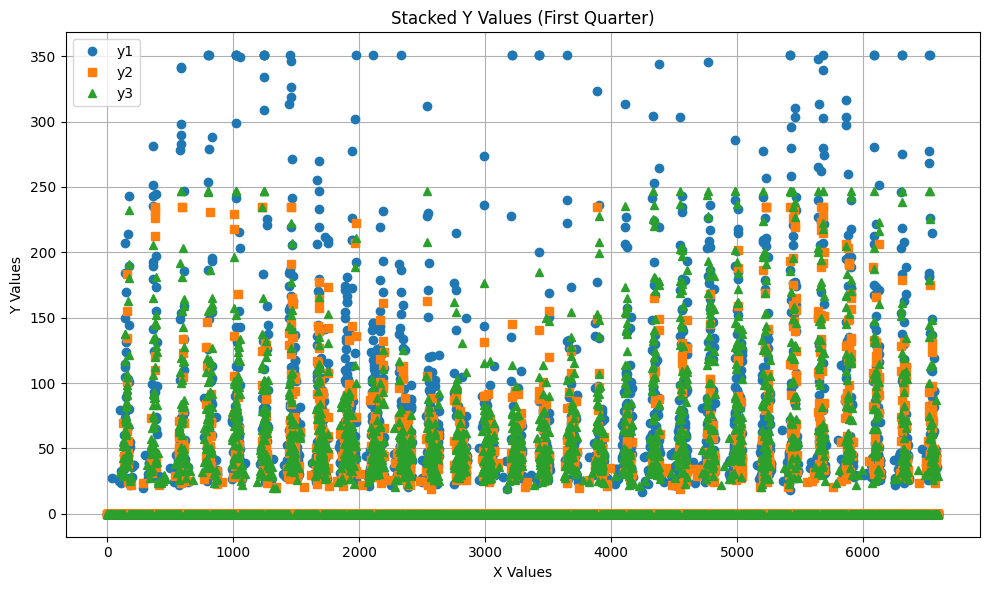

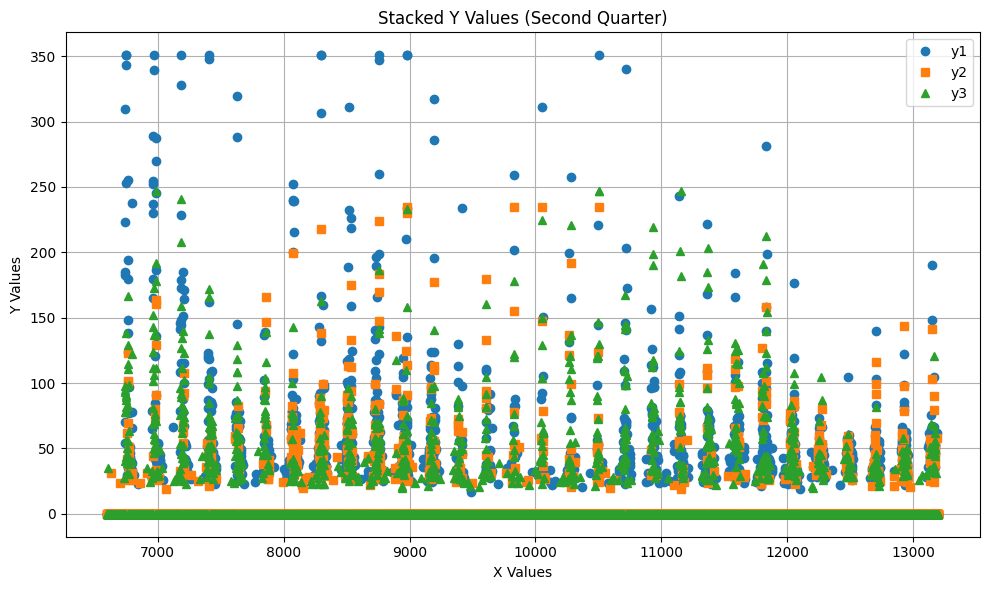

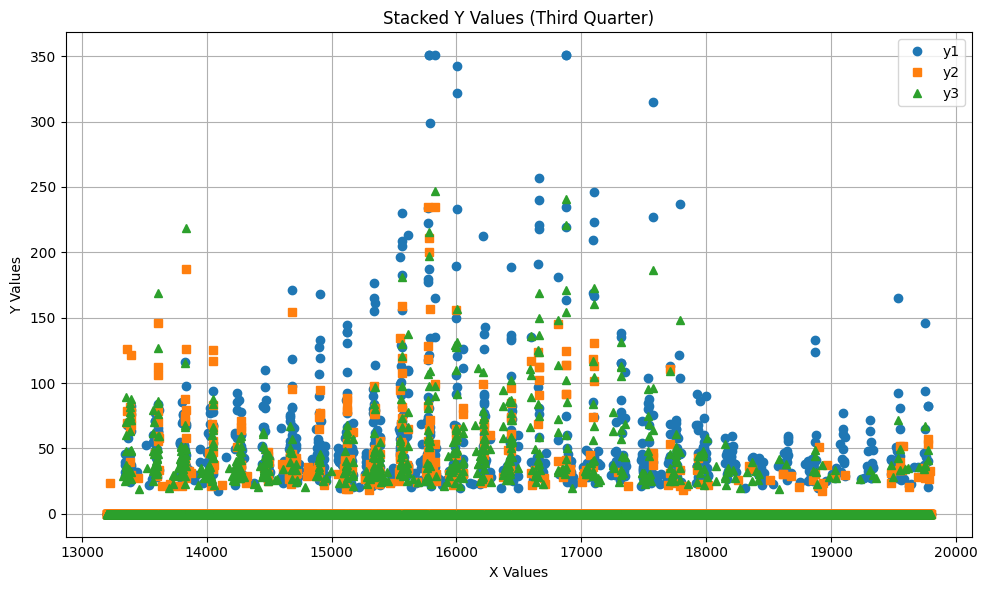

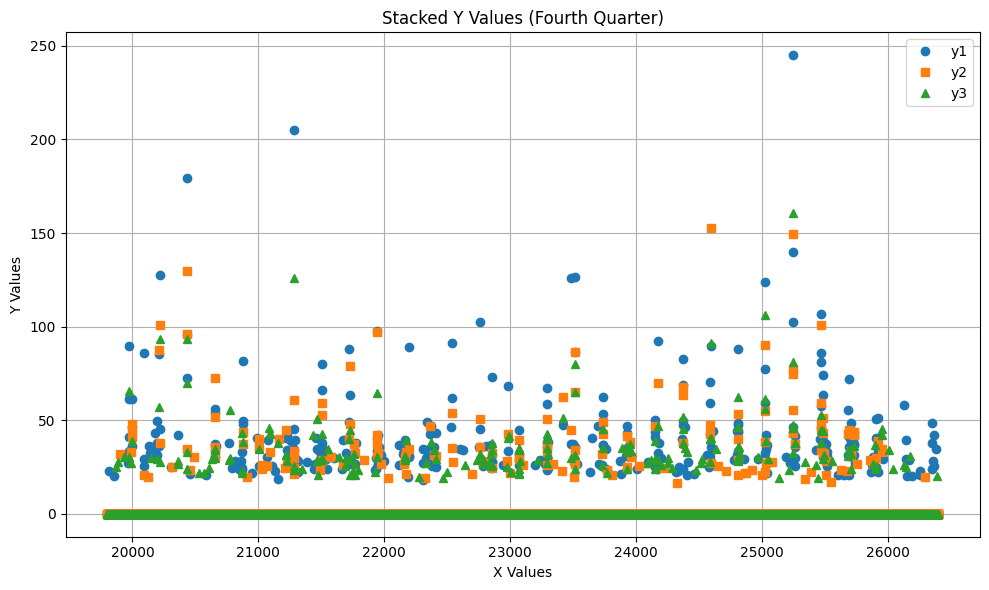

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_stacked_y_values_from_files_quarters(file1, file2, file3):
    """
    Reads data from three CSV files, matches the x-values (first column),
    splits the data into four quarters, and plots the y-values (second column)
    as stacked y-values (points only) for each quarter.

    Parameters
    ----------
    file1 : str
        Path to the first CSV file.
    file2 : str
        Path to the second CSV file.
    file3 : str
        Path to the third CSV file.

    Returns
    -------
    None
    """
    # Read data from the three files
    df1 = pd.read_csv(file1)
    df2 = pd.read_csv(file2)
    df3 = pd.read_csv(file3)

    # Ensure the first column is the x-values and the second column is the y-values
    x1, y1 = df1.iloc[:, 0], df1.iloc[:, 1]
    x2, y2 = df2.iloc[:, 0], df2.iloc[:, 1]
    x3, y3 = df3.iloc[:, 0], df3.iloc[:, 1]

    # Merge the data on the x-values to ensure alignment
    merged_df = pd.DataFrame({file1: y1.values, file2: y2.values, file3: y3.values}, index=x1)

    # Calculate the quarter points
    quarter = len(merged_df) // 4
    first_quarter = merged_df.iloc[:quarter]
    second_quarter = merged_df.iloc[quarter:2 * quarter]
    third_quarter = merged_df.iloc[2 * quarter:3 * quarter]
    fourth_quarter = merged_df.iloc[3 * quarter:]

    # Function to plot a quarter
    def plot_quarter(data, title):
        plt.figure(figsize=(10, 6))
        plt.plot(data.index, data[file1], label='y1', marker='o', linestyle='None')
        plt.plot(data.index, data[file2], label='y2', marker='s', linestyle='None')
        plt.plot(data.index, data[file3], label='y3', marker='^', linestyle='None')
        plt.xlabel('X Values')
        plt.ylabel('Y Values')
        plt.title(title)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    # Plot each quarter
    plot_quarter(first_quarter, 'Stacked Y Values (First Quarter)')
    plot_quarter(second_quarter, 'Stacked Y Values (Second Quarter)')
    plot_quarter(third_quarter, 'Stacked Y Values (Third Quarter)')
    plot_quarter(fourth_quarter, 'Stacked Y Values (Fourth Quarter)')


# Paths to the three CSV files
file1 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_250113_25221_000001/amplitudeMap_t1.csv'
file2 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250114_25221_00012/amplitudeMap_t2.csv'
file3 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250115_25221_000014/amplitudeMap_t3.csv'

# Call the function
plot_stacked_y_values_from_files_quarters(file1, file2, file3)

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def plot_y_value_changes_by_trend(file1, file2, file3, output_path):
    """
    Reads data from three CSV files, matches the x-values (first column),
    and plots x-values whose y-values decrease at the second time point (t2)
    on one plot and x-values that increase at t2 on another. Saves the plots
    to the specified output path and prints the number of x-values in each category.

    Parameters
    ----------
    file1 : str
        Path to the first CSV file (time point 1).
    file2 : str
        Path to the second CSV file (time point 2).
    file3 : str
        Path to the third CSV file (time point 3).
    output_path : str
        Path to the directory where the plots will be saved.

    Returns
    -------
    None
    """
    # Ensure the output directory exists
    os.makedirs(output_path, exist_ok=True)

    # Read data from the three files
    df1 = pd.read_csv(file1)
    df2 = pd.read_csv(file2)
    df3 = pd.read_csv(file3)

    # Ensure the first column is the x-values and the second column is the y-values
    x1, y1 = df1.iloc[:, 0], df1.iloc[:, 1]
    x2, y2 = df2.iloc[:, 0], df2.iloc[:, 1]
    x3, y3 = df3.iloc[:, 0], df3.iloc[:, 1]

    # Merge the data on the x-values to ensure alignment
    merged_df = pd.DataFrame({'x': x1, 'y1': y1, 'y2': y2, 'y3': y3})

    # Separate x-values into two categories based on y2
    decreasing_at_t2 = merged_df[merged_df['y2'] < merged_df['y1']]
    increasing_at_t2 = merged_df[merged_df['y2'] >= merged_df['y1']]

    # Get the number of x-values in each category
    num_decreasing = len(decreasing_at_t2)
    num_increasing = len(increasing_at_t2)

    # Print the number of x-values in each category
    print(f"Number of x-values decreasing at t2: {num_decreasing}")
    print(f"Number of x-values increasing at t2: {num_increasing}")

    # Function to plot a category
    def plot_category(data, title, filename):
        plt.figure(figsize=(10, 6))
        for _, row in data.iterrows():
            plt.plot(['Time 1', 'Time 2', 'Time 3'], [row['y1'], row['y2'], row['y3']], marker='o', label=f"x={row['x']}" if _ == 0 else "")
        plt.xlabel('Time Points')
        plt.ylabel('Y Values')
        plt.title(title)
        plt.legend(title="X Values", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')
        plt.grid(True)
        plt.tight_layout()

        # Save the figure
        save_path = os.path.join(output_path, filename)
        plt.savefig(save_path, dpi=300)
        plt.close()
        print(f"Saved plot: {save_path}")

    # Plot each category and save the figures
    plot_category(decreasing_at_t2, f'X Values with Decreasing Y at t2 (Count: {num_decreasing})', 'decreasing_at_t2.png')
    plot_category(increasing_at_t2, f'X Values with Increasing Y at t2 (Count: {num_increasing})', 'increasing_at_t2.png')


# Paths to the three CSV files
file1 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_chip_250113_25158_00005/amplitudeMap.svg.csv'
file2 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_chip_250115_25183_000010/amplitudeMap.svg.csv'
file3 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_unclear/amplitudeMap.svg.csv'

# Output directory for the plots
output_path = '/Users/allisonpickle/Desktop'

# Call the function
plot_y_value_changes_by_trend(file1, file2, file3, output_path)

Number of x-values decreasing at t2: 947
Number of x-values increasing at t2: 25453


/var/folders/9q/b735k4x1335_j77np9rz8xlc0000gn/T/ipykernel_23325/898514390.py:63: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="X Values", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')


Saved plot: /Users/allisonpickle/Desktop/decreasing_at_t2.png
Saved plot: /Users/allisonpickle/Desktop/increasing_at_t2.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def plot_y_value_changes_by_trend_t2_t3(file1, file2, file3, output_path):
    """
    Reads data from three CSV files, matches the x-values (first column),
    and plots x-values whose y-values decrease between the second time point (t2)
    and the third time point (t3) on one plot and x-values that increase between
    t2 and t3 on another. Saves the plots to the specified output path and prints
    the number of x-values in each category.

    Parameters
    ----------
    file1 : str
        Path to the first CSV file (time point 1).
    file2 : str
        Path to the second CSV file (time point 2).
    file3 : str
        Path to the third CSV file (time point 3).
    output_path : str
        Path to the directory where the plots will be saved.

    Returns
    -------
    None
    """
    # Ensure the output directory exists
    os.makedirs(output_path, exist_ok=True)

    # Read data from the three files
    df1 = pd.read_csv(file1)
    df2 = pd.read_csv(file2)
    df3 = pd.read_csv(file3)

    # Ensure the first column is the x-values and the second column is the y-values
    x1, y1 = df1.iloc[:, 0], df1.iloc[:, 1]
    x2, y2 = df2.iloc[:, 0], df2.iloc[:, 1]
    x3, y3 = df3.iloc[:, 0], df3.iloc[:, 1]

    # Merge the data on the x-values to ensure alignment
    merged_df = pd.DataFrame({'x': x1, 'y1': y1, 'y2': y2, 'y3': y3})

    # Separate x-values into two categories based on y3 compared to y2
    decreasing_at_t3 = merged_df[merged_df['y3'] < merged_df['y2']]
    increasing_at_t3 = merged_df[merged_df['y3'] >= merged_df['y2']]

    # Get the number of x-values in each category
    num_decreasing = len(decreasing_at_t3)
    num_increasing = len(increasing_at_t3)

    # Print the number of x-values in each category
    print(f"Number of x-values decreasing at t3: {num_decreasing}")
    print(f"Number of x-values increasing at t3: {num_increasing}")

    # Function to plot a category
    def plot_category(data, title, filename):
        plt.figure(figsize=(10, 6))
        for _, row in data.iterrows():
            plt.plot(['Time 1', 'Time 2', 'Time 3'], [row['y1'], row['y2'], row['y3']], marker='o', label=f"x={row['x']}" if _ == 0 else "")
        plt.xlabel('Time Points')
        plt.ylabel('Y Values')
        plt.title(title)
        plt.legend(title="X Values", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')
        plt.grid(True)
        plt.tight_layout()

        # Save the figure
        save_path = os.path.join(output_path, filename)
        plt.savefig(save_path, dpi=300)
        plt.close()
        print(f"Saved plot: {save_path}")

    # Plot each category and save the figures
    plot_category(decreasing_at_t3, f'X Values with Decreasing Y at t3 (Count: {num_decreasing})', 'decreasing_at_t3.png')
    plot_category(increasing_at_t3, f'X Values with Increasing Y at t3 (Count: {num_increasing})', 'increasing_at_t3.png')


# Paths to the three CSV files
file1 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_chip_250113_25158_00005/amplitudeMap.svg.csv'
file2 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_chip_250115_25183_000010/amplitudeMap.svg.csv'
file3 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_unclear/amplitudeMap.svg.csv'

# Output directory for the plots
output_path = '/Users/allisonpickle/Desktop'

# Call the function
plot_y_value_changes_by_trend_t2_t3(file1, file2, file3, output_path)

Number of x-values decreasing at t3: 551
Number of x-values increasing at t3: 25849


/var/folders/9q/b735k4x1335_j77np9rz8xlc0000gn/T/ipykernel_23325/625983532.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="X Values", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')


Saved plot: /Users/allisonpickle/Desktop/decreasing_at_t3.png
Saved plot: /Users/allisonpickle/Desktop/increasing_at_t3.png


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def plot_binary_patterns(file1, file2, file3, output_path):
    """
    Reads data from three CSV files, matches the x-values (first column),
    and plots unique binary change patterns (e.g., 0 → 1 → 0) across the three
    time points as separate colored lines. Includes the number of values that
    follow each pattern in the legend.

    Parameters
    ----------
    file1 : str
        Path to the first CSV file (time point 1).
    file2 : str
        Path to the second CSV file (time point 2).
    file3 : str
        Path to the third CSV file (time point 3).
    output_path : str
        Path to the directory where the plot will be saved.

    Returns
    -------
    None
    """
    # Ensure the output directory exists
    os.makedirs(output_path, exist_ok=True)

    # Read data from the three files
    df1 = pd.read_csv(file1)
    df2 = pd.read_csv(file2)
    df3 = pd.read_csv(file3)

    # Ensure the first column is the x-values and the second column is the binary values
    x1, binary1 = df1.iloc[:, 0], df1.iloc[:, 1]
    x2, binary2 = df2.iloc[:, 0], df2.iloc[:, 1]
    x3, binary3 = df3.iloc[:, 0], df3.iloc[:, 1]

    # Convert binary values to integers
    binary1 = binary1.astype(int)
    binary2 = binary2.astype(int)
    binary3 = binary3.astype(int)

    # Merge the data on the x-values to ensure alignment
    merged_df = pd.DataFrame({'x': x1, 'binary1': binary1, 'binary2': binary2, 'binary3': binary3})

    # Create a column for the binary pattern
    merged_df['pattern'] = merged_df.apply(lambda row: f"{row['binary1']} → {row['binary2']} → {row['binary3']}", axis=1)

    # Group by the binary pattern and count the occurrences
    pattern_groups = merged_df.groupby('pattern')

    # Print the number of unique patterns
    print(f"Number of unique binary patterns: {len(pattern_groups)}")

    # Plot each pattern as a single colored line
    plt.figure(figsize=(10, 6))
    for pattern, group in pattern_groups:
        # Plot the pattern as a single line
        plt.plot(['Time 1', 'Time 2', 'Time 3'], [int(pattern.split(' → ')[0]), int(pattern.split(' → ')[1]), int(pattern.split(' → ')[2])],
                 marker='o', label=f"{pattern} (Count: {len(group)})")

    plt.xlabel('Time Points')
    plt.ylabel('Binary Values')
    plt.title(f'Binary Change Patterns Across Time Points (Unique Patterns: {len(pattern_groups)})')
    plt.legend(title="Patterns", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')
    plt.grid(True)
    plt.tight_layout()

    # Save the plot
    save_path = os.path.join(output_path, 'binary_patterns.png')
    plt.savefig(save_path, dpi=300)
    plt.close()
    print(f"Saved plot: {save_path}")


# Paths to the three CSV files
file1 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_chip_250113_25158_00005/isActiveMap.svg.csv'
file2 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_unclear/isActiveMap.svg.csv'
file3 = '/Users/allisonpickle/Desktop/Excel Sheets/Co_chip_250115_25183_000010/isActiveMap.svg.csv'

# Output directory for the plot
output_path = '/Users/allisonpickle/Desktop'

# Call the function
plot_binary_patterns(file1, file2, file3, output_path)

Number of unique binary patterns: 8
Saved plot: /Users/allisonpickle/Desktop/binary_patterns.png


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def plot_binary_patterns(file1, file2, file3, output_path):
    """
    Reads data from three CSV files, matches the x-values (first column),
    and plots unique binary change patterns (e.g., 0 → 1 → 0) across the three
    time points as separate colored lines. Includes the number of values that
    follow each pattern in the legend.

    Parameters
    ----------
    file1 : str
        Path to the first CSV file (time point 1).
    file2 : str
        Path to the second CSV file (time point 2).
    file3 : str
        Path to the third CSV file (time point 3).
    output_path : str
        Path to the directory where the plot will be saved.

    Returns
    -------
    None
    """
    # Ensure the output directory exists
    os.makedirs(output_path, exist_ok=True)

    # Read data from the three files
    df1 = pd.read_csv(file1)
    df2 = pd.read_csv(file2)
    df3 = pd.read_csv(file3)

    # Ensure the first column is the x-values and the second column is the y-values
    x1, y1 = df1.iloc[:, 0], df1.iloc[:, 1]
    x2, y2 = df2.iloc[:, 0], df2.iloc[:, 1]
    x3, y3 = df3.iloc[:, 0], df3.iloc[:, 1]

    # Categorize changes as 1 for increases and 0 for decreases
    binary1 = 0  # Initial binary value (no change at t1)
    binary2 = (y2 > y1).astype(int)  # 1 if y2 > y1, else 0
    binary3 = (y3 > y2).astype(int)  # 1 if y3 > y2, else 0

    # Merge the data on the x-values to ensure alignment
    merged_df = pd.DataFrame({'x': x1, 'binary1': binary1, 'binary2': binary2, 'binary3': binary3})

    # Create a column for the binary pattern
    merged_df['pattern'] = merged_df.apply(lambda row: f"{row['binary1']} → {row['binary2']} → {row['binary3']}", axis=1)

    # Group by the binary pattern and count the occurrences
    pattern_groups = merged_df.groupby('pattern')

    # Print the number of unique patterns
    print(f"Number of unique binary patterns: {len(pattern_groups)}")

    # Plot each pattern as a single colored line
    plt.figure(figsize=(10, 6))
    for pattern, group in pattern_groups:
        # Plot the pattern as a single line
        plt.plot(['Time 1', 'Time 2', 'Time 3'], [int(pattern.split(' → ')[0]), int(pattern.split(' → ')[1]), int(pattern.split(' → ')[2])],
                 marker='o', label=f"{pattern} (Count: {len(group)})")

    plt.xlabel('Time Points')
    plt.ylabel('Binary Values')
    plt.title(f'Binary Change Patterns Across Time Points (Unique Patterns: {len(pattern_groups)})')
    plt.legend(title="Patterns", loc='upper left', bbox_to_anchor=(1, 1), fontsize='small')
    plt.grid(True)
    plt.tight_layout()

    # Save the plot
    save_path = os.path.join(output_path, 'binary_patterns.png')
    plt.savefig(save_path, dpi=300)
    plt.close()
    print(f"Saved plot: {save_path}")


# Paths to the three CSV files
file1 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_250113_25221_000001/amplitudeMap_t1.csv'
file2 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250114_25221_00012/amplitudeMap_t2.csv'
file3 = '/Users/allisonpickle/Desktop/Excel Sheets/Tri_chip_250115_25221_000014/amplitudeMap_t3.csv'

# Output directory for the plot
output_path = '/Users/allisonpickle/Desktop'

# Call the function
plot_binary_patterns(file1, file2, file3, output_path)

Number of unique binary patterns: 4
Saved plot: /Users/allisonpickle/Desktop/binary_patterns.png
